# Figures

## F-Decomposition tunning

### MLP

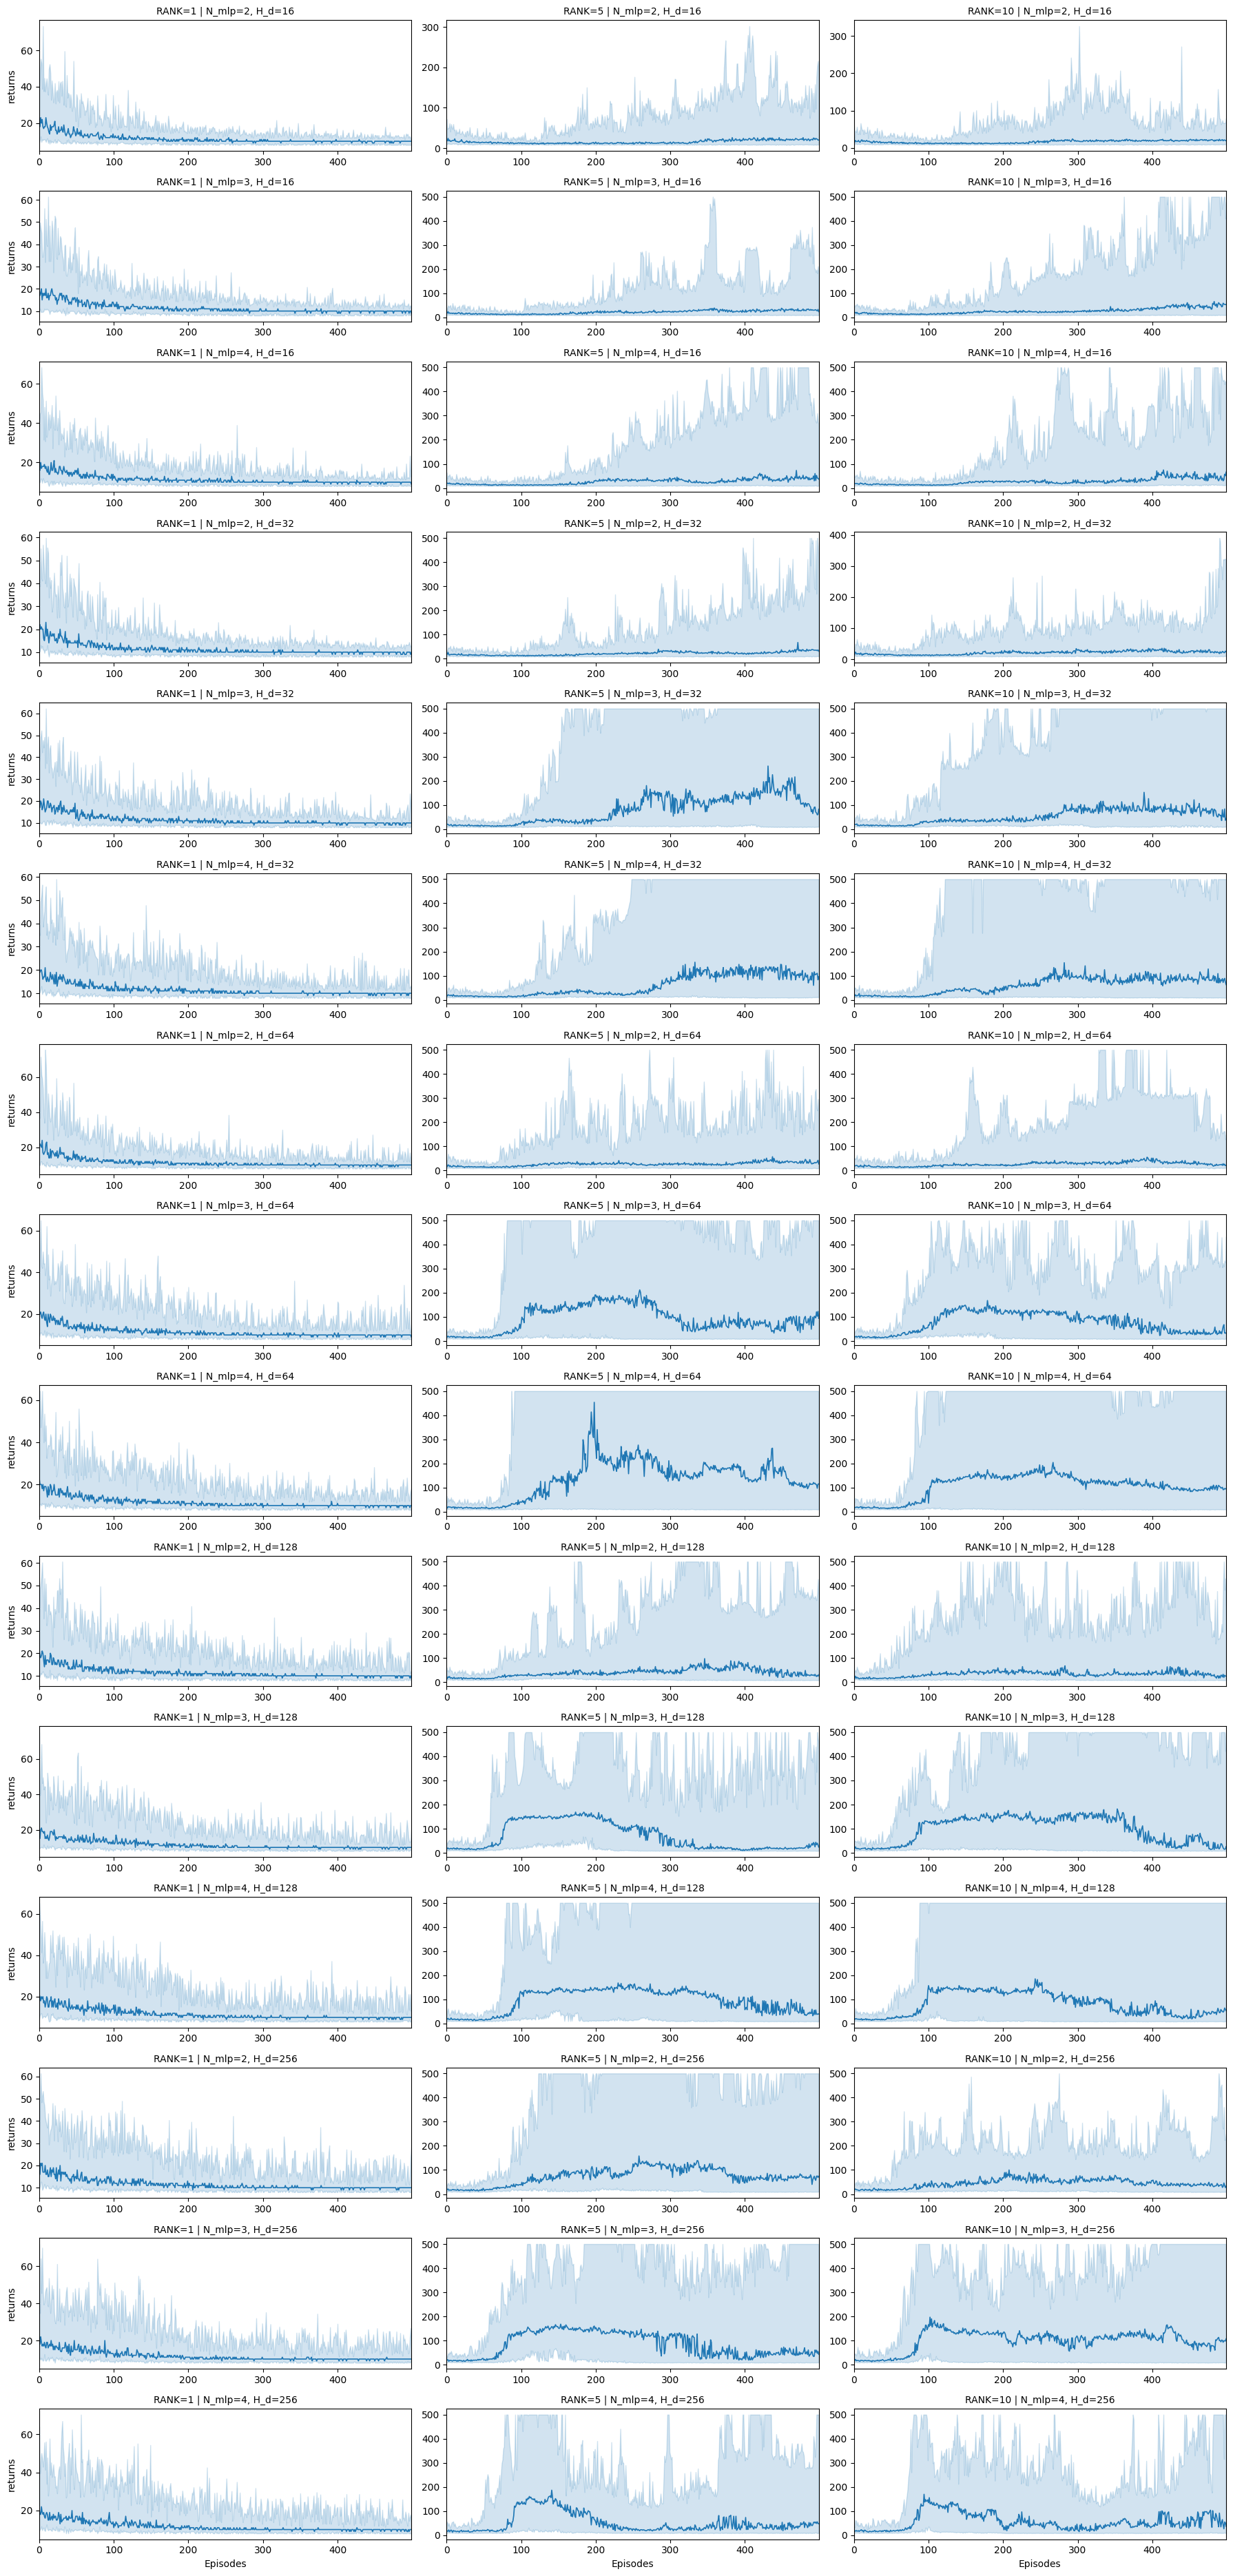

In [1]:
import re
from pathlib import Path
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

# Ruta y configuración
selected_model = "MLP"
results_dir = Path(f"./tunning_exps/F_DECOMPOSITION/{selected_model}/")
color = "tab:blue"

# Mapeo de las 15 subconfiguraciones de MLP (Subconfig 0 a 14)
subconfigs = {
    0: "N_mlp=2, H_d=16",
    1: "N_mlp=3, H_d=16",
    2: "N_mlp=4, H_d=16",
    3: "N_mlp=2, H_d=32",
    4: "N_mlp=3, H_d=32",
    5: "N_mlp=4, H_d=32",
    6: "N_mlp=2, H_d=64",
    7: "N_mlp=3, H_d=64",
    8: "N_mlp=4, H_d=64",
    9: "N_mlp=2, H_d=128",
    10: "N_mlp=3, H_d=128",
    11: "N_mlp=4, H_d=128",
    12: "N_mlp=2, H_d=256",
    13: "N_mlp=3, H_d=256",
    14: "N_mlp=4, H_d=256",
}

# 1. Lectura y cálculo de estadísticas
results = {}
for file_path in results_dir.glob("*.parquet"):
    match = re.search(r"rank(\d+)_subcfg(\d+)", file_path.name)
    if not match:
        continue
    
    rank, subcfg = int(match.group(1)), int(match.group(2))
    df = pq.ParquetFile(file_path).read().to_pandas()
    returns_df = df.filter(like="duration_run_")
    
    results[(rank, subcfg)] = {
        "median": returns_df.median(axis=1),
        "low": returns_df.quantile(0.025, axis=1),
        "high": returns_df.quantile(0.975, axis=1)
    }

# 2. Pintado de la cuadrícula (15 filas x 3 columnas)
ranks = [1, 5, 10]
subcfgs = list(range(15))
n_rows, n_cols = len(subcfgs), len(ranks)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 2.5 * n_rows), squeeze=False)

for i, subcfg in enumerate(subcfgs):
    for j, rank in enumerate(ranks):
        ax = axes[i, j]
        key = (rank, subcfg)
        
        if key in results:
            stats = results[key]
            x = stats["median"].index
            
            ax.plot(x, stats["median"], color=color, linewidth=1.2)
            ax.fill_between(x, stats["low"], stats["high"], alpha=0.2, color=color)
            
            ax.set_xlim(x.min(), x.max())
            ax.set_title(f"RANK={rank} | {subconfigs[subcfg]}", fontsize=10)
            
            if i == n_rows - 1:
                ax.set_xlabel("Episodes")
            if j == 0:
                ax.set_ylabel("returns")
        else:
            ax.axis("off")

plt.tight_layout()
plt.show()

### FF-MLP

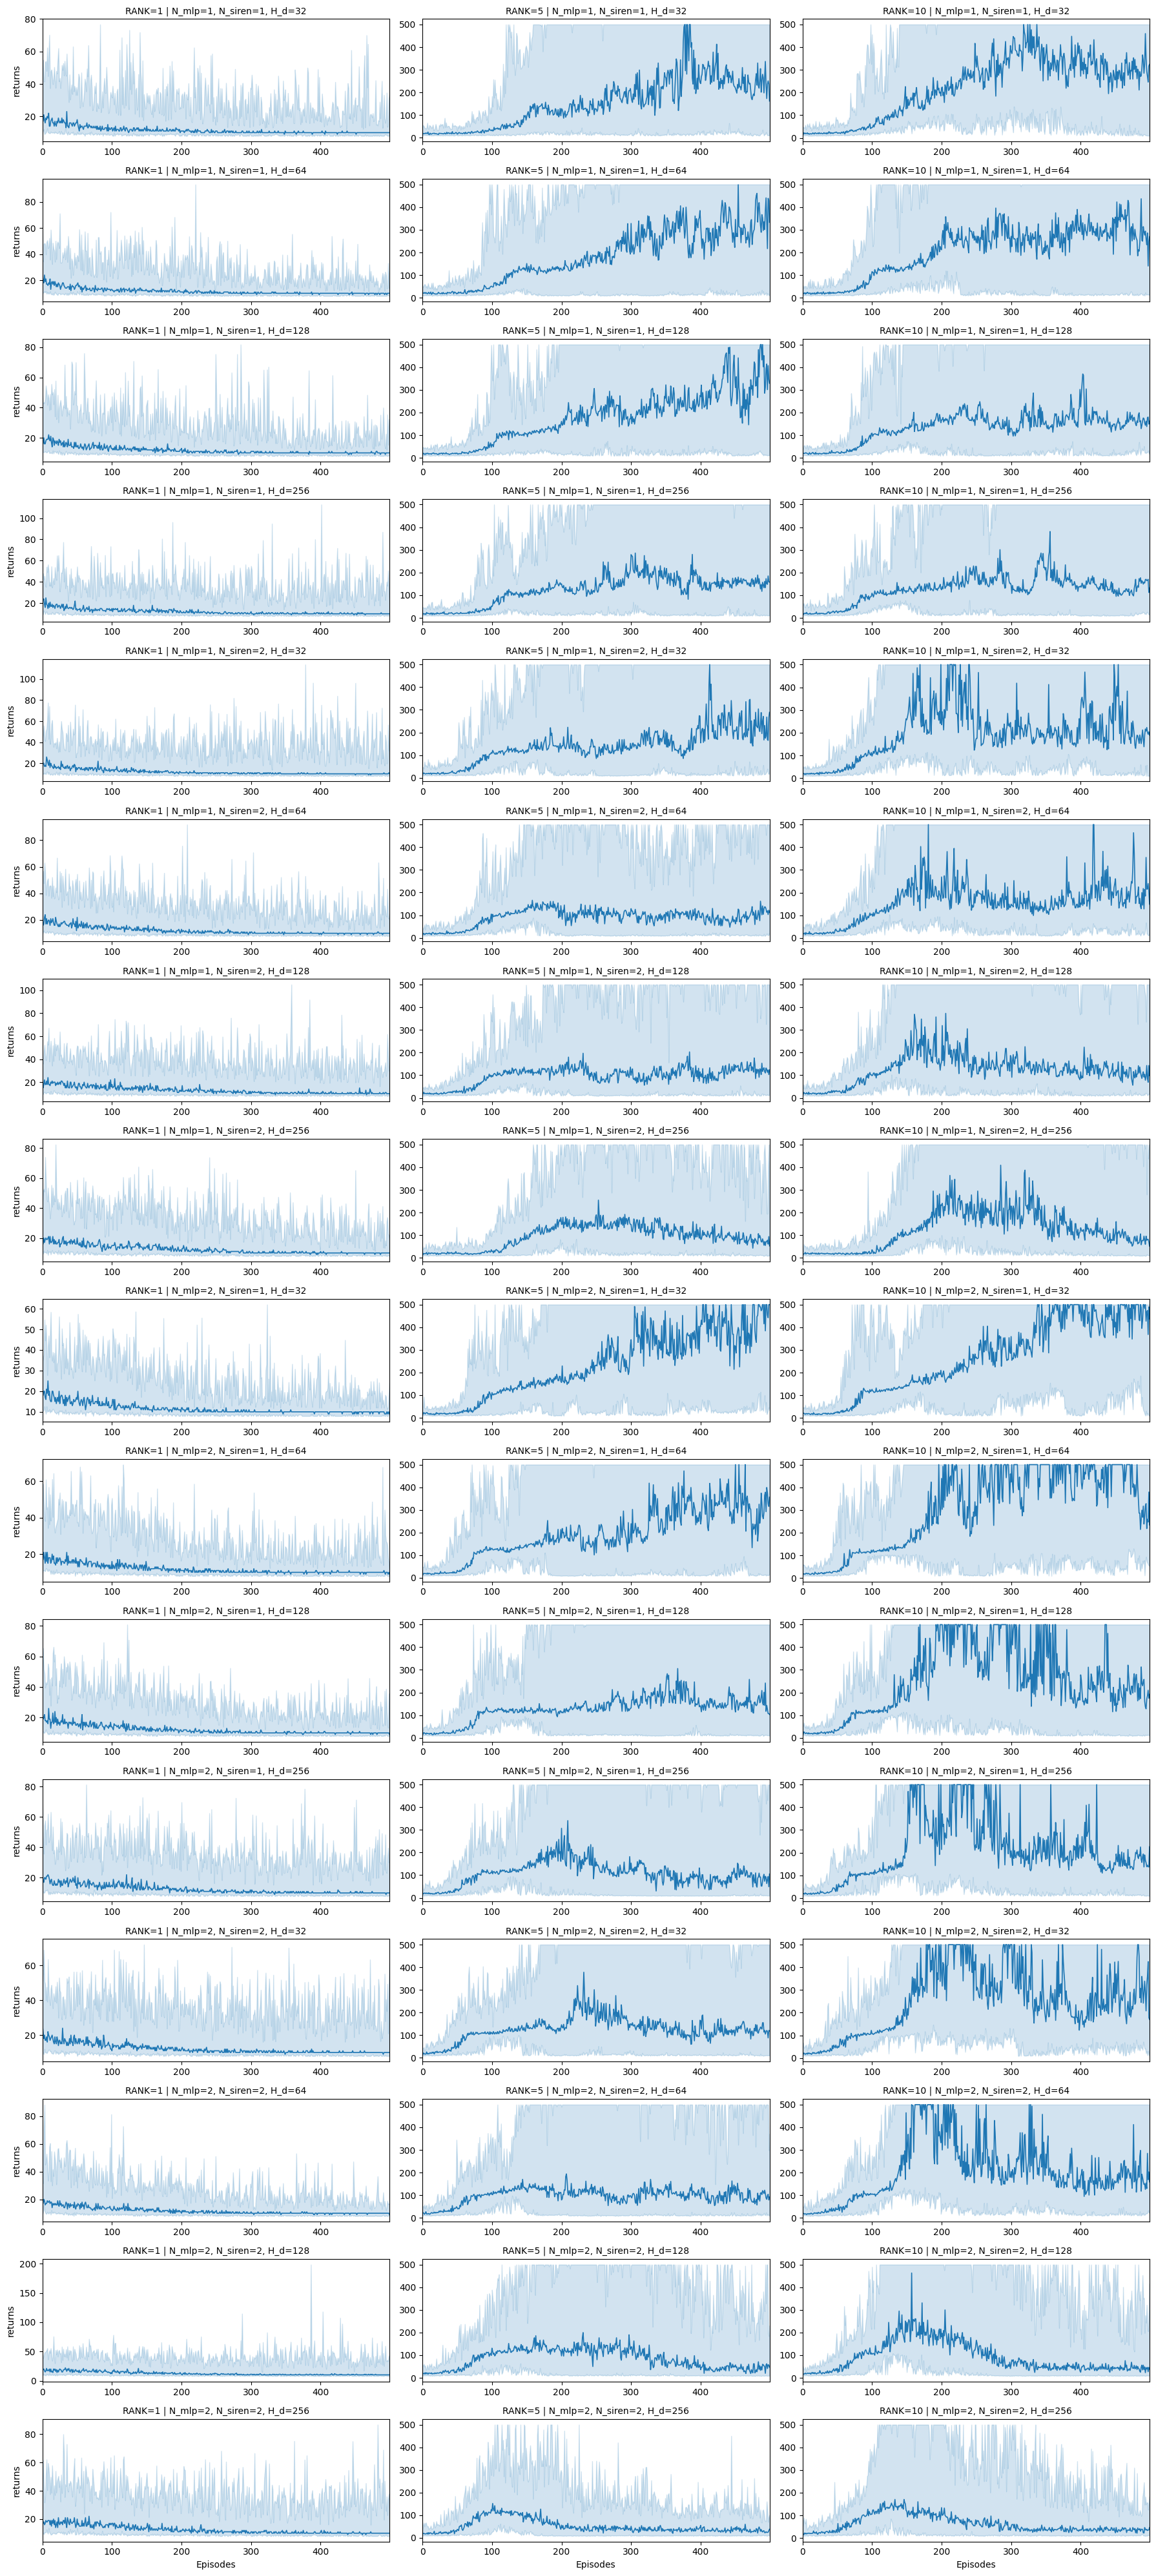

In [2]:
import re
from pathlib import Path
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

# Ruta y configuración
selected_model = "SIRENMLP"
results_dir = Path(f"./tunning_exps/F_DECOMPOSITION/{selected_model}/")
color = "tab:blue"

# Mapeo de las 16 subconfiguraciones con los nuevos nombres
subconfigs = {
    0: "N_mlp=1, N_siren=1, H_d=32",
    1: "N_mlp=1, N_siren=1, H_d=64",
    2: "N_mlp=1, N_siren=1, H_d=128",
    3: "N_mlp=1, N_siren=1, H_d=256",
    4: "N_mlp=1, N_siren=2, H_d=32",
    5: "N_mlp=1, N_siren=2, H_d=64",
    6: "N_mlp=1, N_siren=2, H_d=128",
    7: "N_mlp=1, N_siren=2, H_d=256",
    8: "N_mlp=2, N_siren=1, H_d=32",
    9: "N_mlp=2, N_siren=1, H_d=64",
    10: "N_mlp=2, N_siren=1, H_d=128",
    11: "N_mlp=2, N_siren=1, H_d=256",
    12: "N_mlp=2, N_siren=2, H_d=32",
    13: "N_mlp=2, N_siren=2, H_d=64",
    14: "N_mlp=2, N_siren=2, H_d=128",
    15: "N_mlp=2, N_siren=2, H_d=256",
}

# 1. Lectura y cálculo de estadísticas
results = {}
for file_path in results_dir.glob("*.parquet"):
    match = re.search(r"rank(\d+)_subcfg(\d+)", file_path.name)
    if not match:
        continue
    
    rank, subcfg = int(match.group(1)), int(match.group(2))
    df = pq.ParquetFile(file_path).read().to_pandas()
    returns_df = df.filter(like="duration_run_")
    
    results[(rank, subcfg)] = {
        "median": returns_df.median(axis=1),
        "low": returns_df.quantile(0.025, axis=1),
        "high": returns_df.quantile(0.975, axis=1)
    }

# 2. Pintado de la cuadrícula (16 filas x 3 columnas)
ranks = [1, 5, 10]
subcfgs = list(range(16))
n_rows, n_cols = len(subcfgs), len(ranks)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 2.5 * n_rows), squeeze=False)

for i, subcfg in enumerate(subcfgs):
    for j, rank in enumerate(ranks):
        ax = axes[i, j]
        key = (rank, subcfg)
        
        if key in results:
            stats = results[key]
            x = stats["median"].index
            
            ax.plot(x, stats["median"], color=color, linewidth=1.2)
            ax.fill_between(x, stats["low"], stats["high"], alpha=0.2, color=color)
            
            ax.set_xlim(x.min(), x.max())
            ax.set_title(f"RANK={rank} | {subconfigs[subcfg]}", fontsize=10)
            
            if i == n_rows - 1:
                ax.set_xlabel("Episodes")
            if j == 0:
                ax.set_ylabel("returns")
        else:
            ax.axis("off")

plt.tight_layout()
plt.show()

# FF-MLP with residual & lnorm

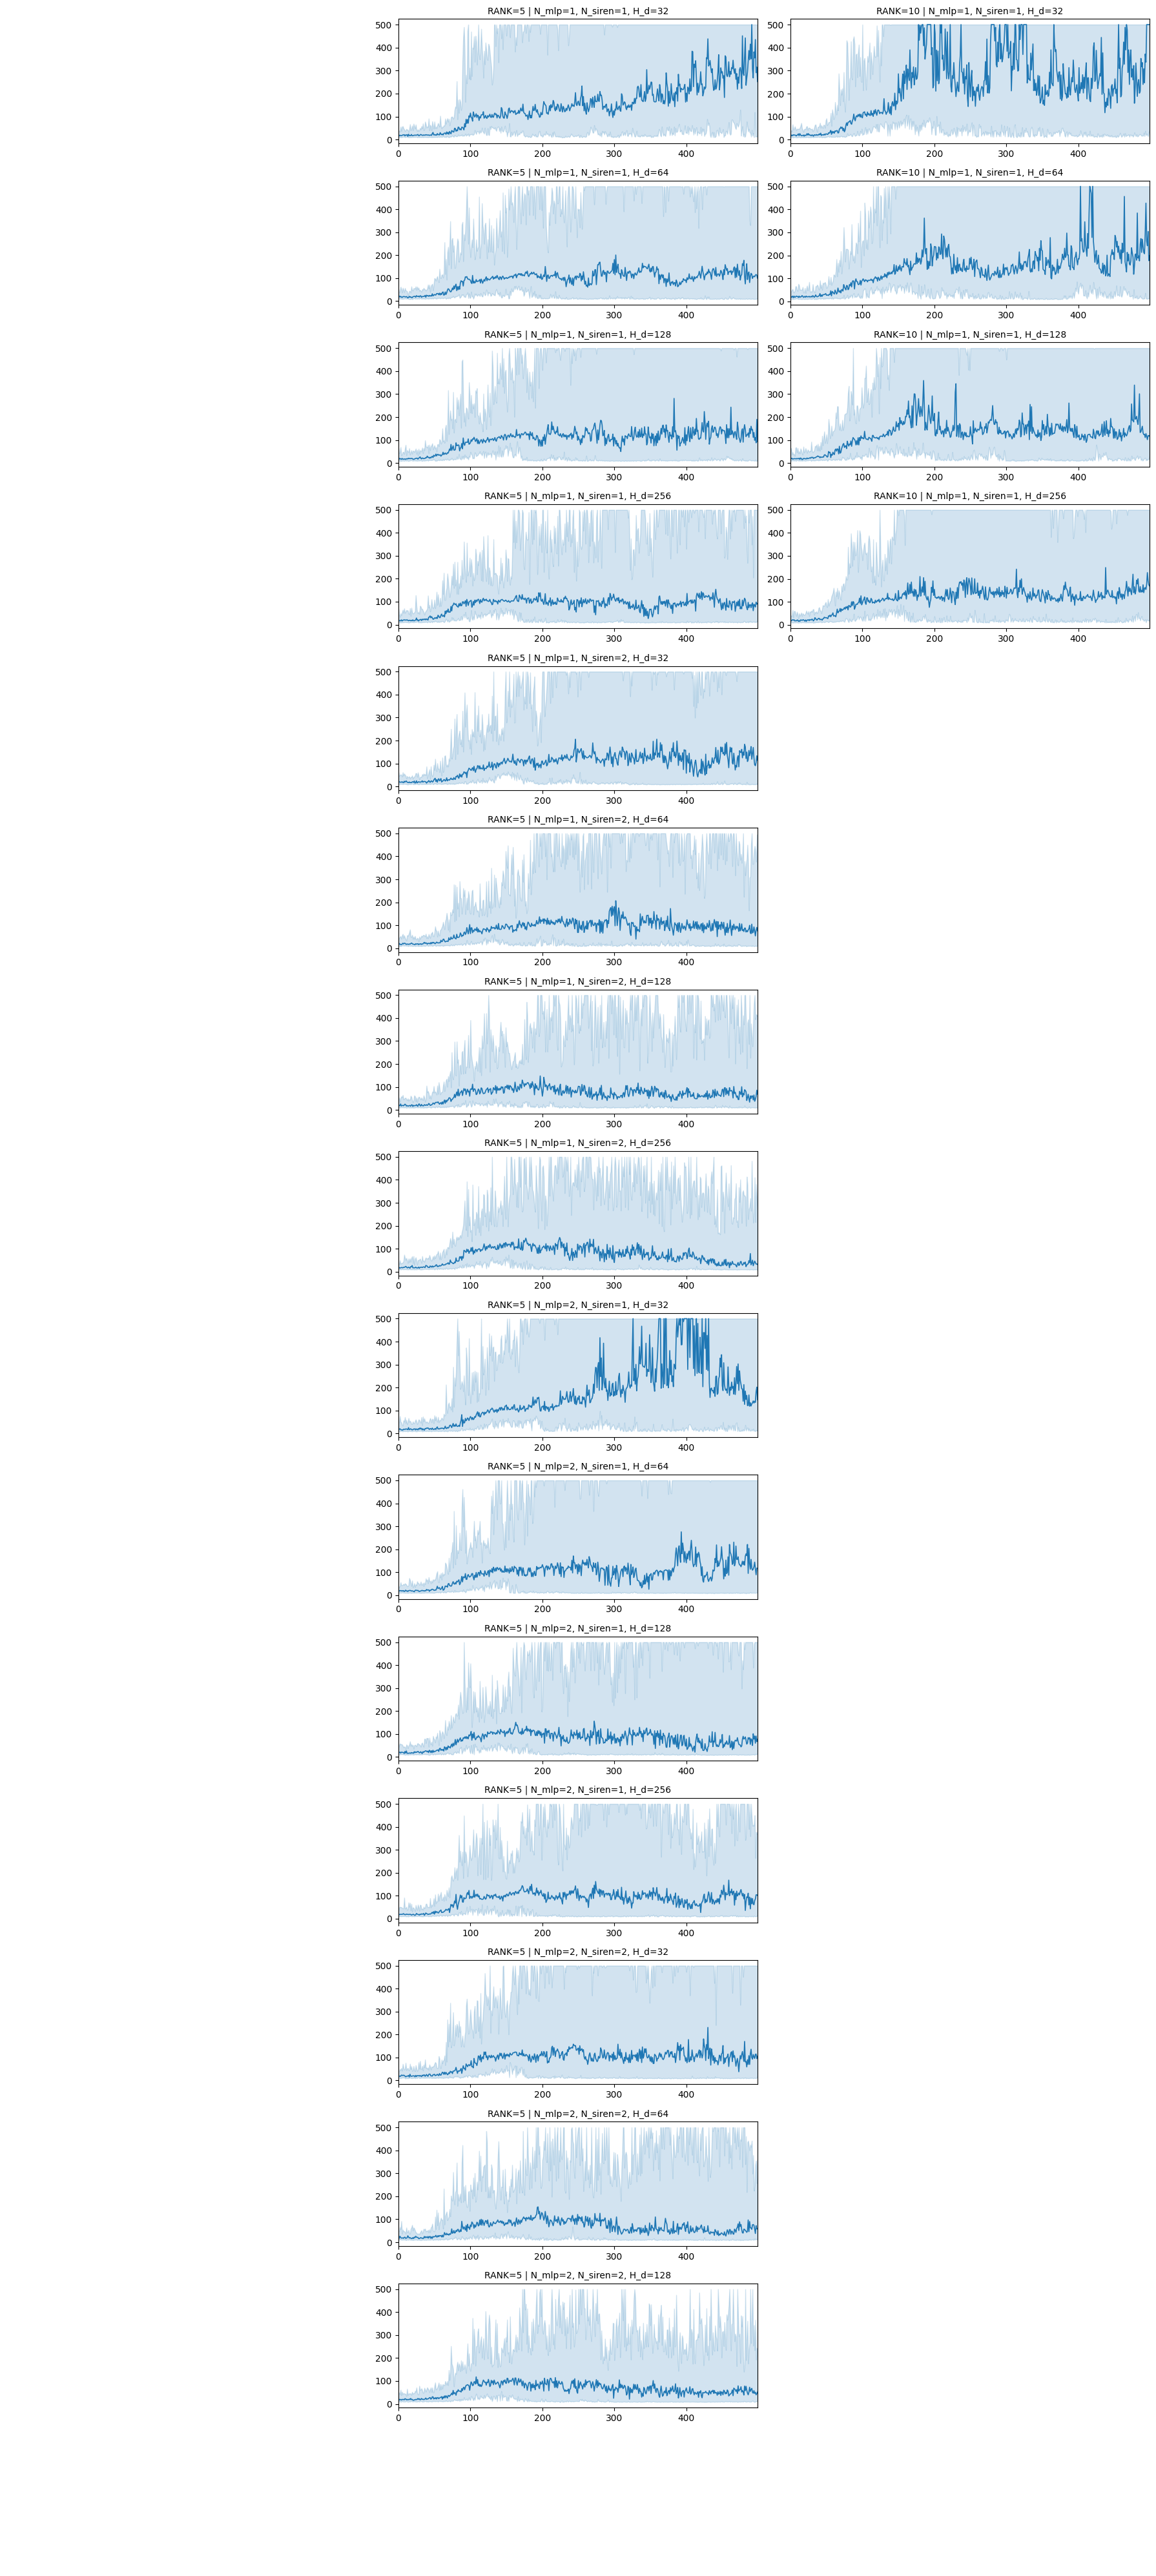

In [1]:
import re
from pathlib import Path
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

# Ruta y configuración
selected_model = "SIRENMLP_V2"
results_dir = Path(f"./tunning_exps/F_DECOMPOSITION/{selected_model}/")
color = "tab:blue"

# Mapeo de las 16 subconfiguraciones con abreviaturas (N_mlp y N_siren)
subconfigs = {
    0: "N_mlp=1, N_siren=1, H_d=32",
    1: "N_mlp=1, N_siren=1, H_d=64",
    2: "N_mlp=1, N_siren=1, H_d=128",
    3: "N_mlp=1, N_siren=1, H_d=256",
    4: "N_mlp=1, N_siren=2, H_d=32",
    5: "N_mlp=1, N_siren=2, H_d=64",
    6: "N_mlp=1, N_siren=2, H_d=128",
    7: "N_mlp=1, N_siren=2, H_d=256",
    8: "N_mlp=2, N_siren=1, H_d=32",
    9: "N_mlp=2, N_siren=1, H_d=64",
    10: "N_mlp=2, N_siren=1, H_d=128",
    11: "N_mlp=2, N_siren=1, H_d=256",
    12: "N_mlp=2, N_siren=2, H_d=32",
    13: "N_mlp=2, N_siren=2, H_d=64",
    14: "N_mlp=2, N_siren=2, H_d=128",
    15: "N_mlp=2, N_siren=2, H_d=256",
}

# 1. Lectura y cálculo de estadísticas
results = {}
for file_path in results_dir.glob("*.parquet"):
    match = re.search(r"rank(\d+)_subcfg(\d+)", file_path.name)
    if not match:
        continue
    
    rank, subcfg = int(match.group(1)), int(match.group(2))
    df = pq.ParquetFile(file_path).read().to_pandas()
    returns_df = df.filter(like="duration_run_")
    
    results[(rank, subcfg)] = {
        "median": returns_df.median(axis=1),
        "low": returns_df.quantile(0.025, axis=1),
        "high": returns_df.quantile(0.975, axis=1)
    }

# 2. Pintado de la cuadrícula (16 filas x 3 columnas)
ranks = [1, 5, 10]
subcfgs = list(range(16))
n_rows, n_cols = len(subcfgs), len(ranks)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 2.5 * n_rows), squeeze=False)

for i, subcfg in enumerate(subcfgs):
    for j, rank in enumerate(ranks):
        ax = axes[i, j]
        key = (rank, subcfg)
        
        if key in results:
            stats = results[key]
            x = stats["median"].index
            
            ax.plot(x, stats["median"], color=color, linewidth=1.2)
            ax.fill_between(x, stats["low"], stats["high"], alpha=0.2, color=color)
            
            ax.set_xlim(x.min(), x.max())
            ax.set_title(f"RANK={rank} | {subconfigs[subcfg]}", fontsize=10)
            
            if i == n_rows - 1:
                ax.set_xlabel("Episodes")
            if j == 0:
                ax.set_ylabel("returns")
        else:
            ax.axis("off")

plt.tight_layout()
plt.show()